# 20 · 项目部署（Docker）

来源：[飞书讲义《20-项目部署(Docker)》](https://heuqqdmbyk.feishu.cn/wiki/GAwGwd0GHibOovkLpH3cjpMwnVm)。本章学习 Docker 容器化基础、镜像与容器管理、Dockerfile 和 Docker Compose，并把 Tlias 前后端项目及其依赖部署到 Docker 环境。

整理日期：2026-10-06。讲义中的 Docker 命令、配置片段、部署代码和配图按原顺序内嵌；补充内容单独标注。

## 本章跟练路线（补充）

| 顺序 | 目标 | 关键产物 | 验收点 |
| --- | --- | --- | --- |
| 1 | 准备 Docker 环境 | Docker Engine、Compose、镜像仓库 | `docker version` 与 `docker compose version` 可用 |
| 2 | 管理镜像与容器 | `pull`、`build`、`run`、`ps`、`logs` | 能启动、查看和停止容器 |
| 3 | 编写镜像构建文件 | Dockerfile、构建上下文、分层缓存 | 能构建可运行的前后端镜像 |
| 4 | 编排多服务 | Compose、网络、卷、环境变量 | 前端、后端、MySQL、Nginx 能协同启动 |
| 5 | 持久化与配置 | volumes、bind mount、`.env` | 容器重建后数据和配置仍然可恢复 |
| 6 | 部署前端 | Vue 构建、Nginx 静态资源、反向代理 | 浏览器能访问页面，history 路由可刷新 |
| 7 | 部署后端 | Spring Boot 镜像、健康检查、日志 | 接口可访问，服务异常能定位并重启 |

### 部署调用链

```text
前端源码 -> Dockerfile 构建 -> Nginx 容器托管静态资源
后端源码 -> Maven 打包 -> JDK 镜像运行 Spring Boot
docker compose up -> 创建网络/卷/容器 -> 前端代理 -> 后端 -> MySQL/OSS
```

**讲义提示**

> 如果大家在自学的过程中，时间紧迫、没有方向、经常遇到难以解决的Bug、没有亮眼的项目、缺少AI大模型经验，而又想快速系统化的学习，高薪就业的小伙伴儿，大家都可以 🔗直接点我 ，了解一下我们系统化的课程体系。

在昨天的课程中，我们学习了Linux操作系统的常见命令，在Linux上安装软件，以及如何在Linux上部署一个单体项目。大家想一想自己最大的感受是什么？

我相信，除了个别天赋异禀的同学以外，大多数同学都会有相同的感受，那就是麻烦。核心体现在三点：

- 命令太多了，记不住

- 软件安装包名字复杂，不知道去哪里找

- 安装和部署步骤复杂，容易出错

其实上述问题不仅仅是新手，即便是运维在安装、部署的时候一样会觉得麻烦、容易出错 。

特别是我们即将进入项目阶段的学习，项目动辄就是几台、几十台、甚至上百台服务需要部署，有些大型项目甚至达到成千上万台服务。而由于每台服务器的运行环境不同，你写好的安装流程、部署脚本并不一定在每个服务器都能正常运行，经常会出错。这就给系统的部署运维带来了很多困难 。

那么，有没有一种技术能够避免部署对服务器环境的依赖，减少复杂的部署流程呢？

答案是肯定的，这就是我们今天要学习的Docker技术。你会发现，有了Docker以后项目的部署如丝般顺滑，大大减少了运维工作量。

即便你对Linux不熟悉，你也能轻松部署各种常见软件、Java项目。

**讲义提示**

> 通过今天的学习，大家要能够达成下面的学习目标：

> - 能利用Docker部署常见软件

> - 能利用Docker打包并部署Java应用

> - 理解Docker数据卷的基本作用

> - 能看懂DockerCompose文件

## 快速入门

> **补充｜环境检查。** 先执行 `docker version`、`docker info` 和 `docker compose version`，确认客户端、Docker daemon 与 Compose 均可用。

要想让Docker帮我们安装和部署软件，肯定要保证你的机器上有Docker。由于大家的操作系统各不相同，安装方式也不同。为了便于大家学习，我们统一在之前提供给大家的CentOS的虚拟机中已经安装了Docker，统一学习环境。

如果大家需要自己在别的机器上安装Docker环境，可以参照最后的 附录中的：Docker安装文档

### 部署MySQL

> **补充｜数据持久化。** 示例命令适合快速体验；正式环境应为 `/var/lib/mysql` 配置 named volume，并通过环境变量或密钥管理注入密码，避免把敏感值写进命令历史。

首先，我们利用Docker来安装一个MySQL软件，大家可以对比一下之前传统的安装方式，看看哪个效率更高一些。

如果是利用传统方式部署MySQL，大概的步骤有：

- 搜索并下载MySQL安装包

- 上传至Linux环境

- 解压和配置环境

- 安装

- 初始化和配置

而使用Docker安装，仅仅需要一步即可，在命令行输入下面的命令（建议采用CV大法）：

```powershell
docker run -d \
  --name mysql \
  -p 3307:3306 \
  -e TZ=Asia/Shanghai \
  -e MYSQL_ROOT_PASSWORD=123 \
  mysql:8
```

运行效果如图（在给大家提供的资料中，已经下载好了mysql 8版本的镜像）：

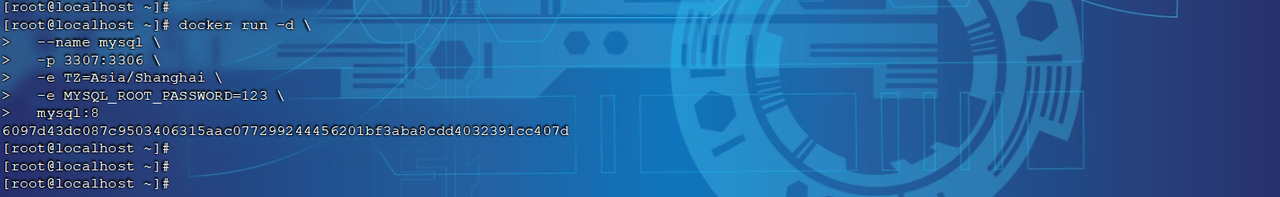

MySQL安装完毕！通过任意客户端工具即可连接到MySQL。

说明：

其实，当我们执行命令后，Docker做的第一件事情，是去自动搜索并下载了MySQL，然后会自动运行MySQL，我们完全不用插手，是非常方便的 。

而且，这种安装方式你完全不用考虑运行的操作系统环境，它不仅仅在CentOS系统是这样，在Ubuntu系统、macOS系统、甚至是装了WSL的Windows下，都可以使用这条命令来安装MySQL 。

要知道，不同操作系统下其安装包、运行环境是都不相同的！如果是手动安装，必须手动解决安装包不同、环境不同的、配置不同的问题！

而使用Docker，这些完全不用考虑。就是因为Docker会自动搜索并下载MySQL。

注意：

这里下载的不是安装包，而是镜像。镜像中不仅包含了MySQL本身，还包含了其运行所需要的环境、配置、系统级函数库。因此它在运行时就有自己独立的环境，就可以跨系统运行，也不需要手动再次配置环境了。这套独立运行的隔离环境我们称为容器。

说明：

- 镜像：英文是image

- 容器：英文是container

**讲义提示**

> **讲义提示**

> 因此，Docker安装软件的过程，就是自动搜索下载镜像，然后创建并运行容器的过程。

Docker会根据命令中的镜像名称自动搜索并下载镜像，那么问题来了，它是去哪里搜索和下载镜像的呢？这些镜像又是谁制作的呢？

Docker官方提供了一个专门管理、存储镜像的网站，并对外开放了镜像上传、下载的权利。Docker官方提供了一些基础镜像，然后各大软件公司又在基础镜像基础上，制作了自家软件的镜像，全部都存放在这个网站。这个网站就成了Docker镜像交流的社区：https://hub.docker.com

基本上我们常用的各种软件都能在这个网站上找到，我们甚至可以自己制作镜像上传上去。【但是该网站，目前国内上不去了】

像这种提供存储、管理Docker镜像的服务器，被称为DockerRegistry，可以翻译为镜像仓库。DockerHub网站是官方仓库，阿里云、华为云会提供一些第三方仓库，我们也可以自己搭建私有的镜像仓库。

官方仓库在国外，下载速度较慢，一般我们都会使用第三方仓库提供的镜像加速功能，提高下载速度。而企业内部的机密项目，往往会采用私有镜像仓库。

总之，镜像的来源有两种：

- 基于官方基础镜像自己制作

- 直接去DockerRegistry下载

**讲义提示**

> 总结一下：

> Docker本身包含一个后台服务，我们可以利用Docker命令告诉Docker服务，帮助我们快速部署指定的应用。Docker服务部署应用时，首先要去搜索并下载应用对应的镜像，然后根据镜像创建并允许容器，应用就部署完成了。

用一幅图表示如下：

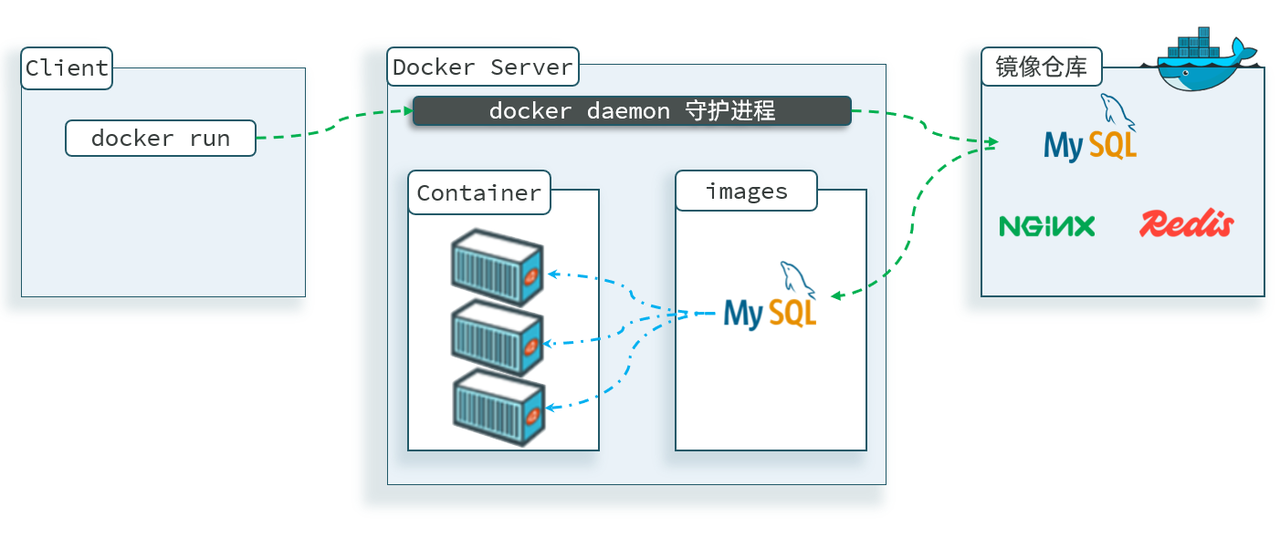

### 命令解读

> **补充｜端口映射。** `-p 主机端口:容器端口` 只改变访问入口，不改变容器内服务监听端口；排查时同时检查容器状态、端口映射和应用日志。

利用Docker快速的安装了MySQL，非常的方便，不过我们执行的命令到底是什么意思呢？

```powershell
docker run -d \
  --name mysql \
  -p 3307:3306 \
  -e TZ=Asia/Shanghai \
  -e MYSQL_ROOT_PASSWORD=123 \
  mysql:8
```

**讲义提示**

> **讲义提示**

> 解读：

> - docker run -d ：创建并运行一个容器，-d则是让容器以后台进程运行

> - --name mysql  : 给容器起个名字叫mysql，你可以叫别的

> - -p 3307:3306 : 设置端口映射。

> - 容器是隔离环境，外界不可访问。但是可以将宿主机端口映射容器内到端口，当访问宿主机指定端口时，就是在访问容器内的端口了。

> - 容器内端口往往是由容器内的进程决定，例如MySQL进程默认端口是3306，因此容器内端口一定是3306；而宿主机端口则可以任意指定，一般与容器内保持一致。

> - 格式： -p 宿主机端口:容器内端口，示例中就是将宿主机的3307映射到容器内的3306端口

> - -e TZ=Asia/Shanghai : 配置容器内进程运行时的一些参数

> - 格式：-e KEY=VALUE，KEY和VALUE都由容器内进程决定

> - 案例中，TZ=Asia/Shanghai是设置时区；MYSQL_ROOT_PASSWORD=123是设置MySQL默认密码

> - mysql:8 : 设置镜像名称，Docker会根据这个名字搜索并下载镜像

> - 格式：REPOSITORY:TAG，例如mysql:8.0，其中REPOSITORY可以理解为镜像名，TAG是版本号

> - 在未指定TAG的情况下，默认是最新版本，也就是mysql:latest

镜像的名称不是随意的，而是要到DockerRegistry中寻找，镜像运行时的配置也不是随意的，要参考镜像的帮助文档，这些在DockerHub网站或者软件的官方网站中都能找到。

如果我们要安装其它软件，也可以到DockerRegistry中寻找对应的镜像名称和版本，阅读相关配置即可。

## Docker基础

> **补充｜镜像与容器。** 镜像是只读模板，容器是镜像运行后的实例。容器删除后其中未挂载的数据会消失，因此状态数据必须放到数据卷。

接下来，我们一起来学习Docker使用的一些基础知识，为将来部署项目打下基础。

### 常见命令

> **补充｜排障顺序。** 先用 `docker ps -a` 看状态，再用 `docker logs` 看日志，必要时用 `docker exec -it` 进入容器检查配置和网络。

#### 命令介绍

其中，比较常见的命令有：

| 列1 | 列2 | 列3 |
| --- | --- | --- |
| 命令 | 说明 | 文档地址 |
| docker pull | 拉取镜像 | docker pull |
| docker push | 推送镜像到DockerRegistry | docker push |
| docker images | 查看本地镜像 | docker images |
| docker rmi | 删除本地镜像 | docker rmi |
| docker run | 创建并运行容器（不能重复创建） | docker run |
| docker stop | 停止指定容器 | docker stop |
| docker start | 启动指定容器 | docker start |
| docker restart | 重新启动容器 | docker restart |
| docker rm | 删除指定容器 | docs.docker.com |
| docker ps | 查看容器 | docker ps |
| docker logs | 查看容器运行日志 | docker logs |
| docker exec | 进入容器 | docker exec |
| docker save | 保存镜像到本地压缩文件 | docker save |
| docker load | 加载本地压缩文件到镜像 | docker load |
| docker inspect | 查看容器详细信息 | docker inspect |

用一副图来表示这些命令的关系：

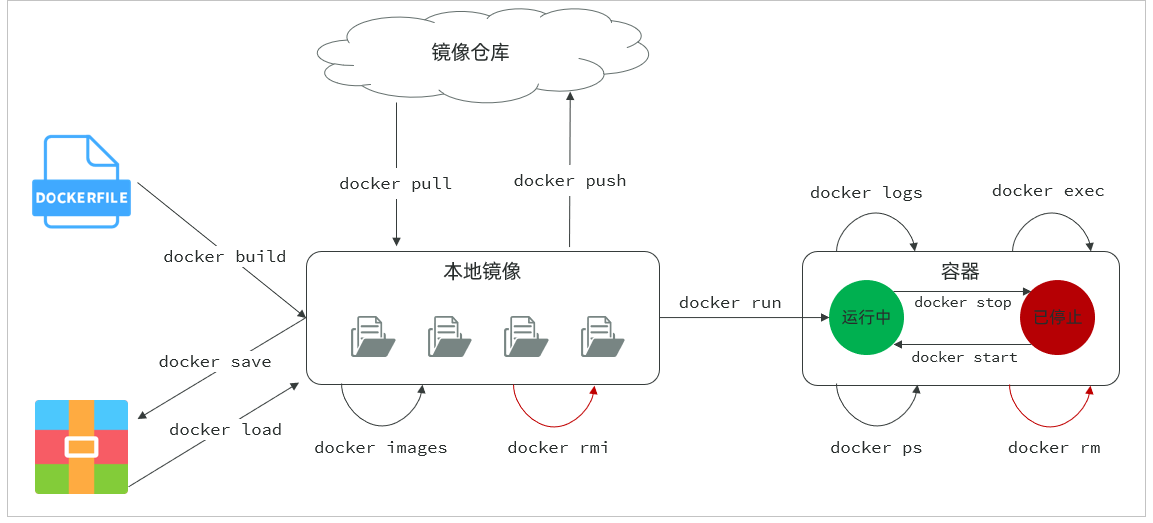

补充：

默认情况下，每次重启虚拟机我们都需要手动启动Docker和Docker中的容器。通过命令可以实现开机自启：

```powershell
# Docker开机自启
systemctl enable docker

# Docker容器开机自启
docker update --restart=always [容器名/容器id]
```

#### 演示

我们以Nginx为例给大家演示上述命令。

```powershell
# 第1步，去DockerHub查看nginx镜像仓库及相关信息

# 第2步，拉取Nginx镜像 (比较耗时)
docker pull nginx:1.20.2

# 第3步，查看镜像
docker images

# 第4步，创建并允许Nginx容器
docker run -d --name nginx -p 80:80 nginx

# 第5步，查看运行中容器
docker ps

# 也可以加格式化方式访问，格式会更加清爽
docker ps --format "table {{.ID}}\t{{.Image}}\t{{.Ports}}\t{{.Status}}\t{{.Names}}"

# 第6步，访问网页，地址：http://虚拟机地址

# 第7步，停止容器
docker stop nginx

# 第8步，查看所有容器
docker ps -a --format "table {{.ID}}\t{{.Image}}\t{{.Ports}}\t{{.Status}}\t{{.Names}}"

# 第9步，再次启动nginx容器
docker start nginx

# 第10步，再次查看容器
docker ps --format "table {{.ID}}\t{{.Image}}\t{{.Ports}}\t{{.Status}}\t{{.Names}}"

# 第11步，查看容器详细信息
docker inspect nginx

# 第12步，进入容器,查看容器内目录
docker exec -it nginx bash

# 或者，可以进入MySQL
docker exec -it mysql mysql -uroot -p

# 第13步，删除容器
docker rm nginx

# 发现无法删除，因为容器运行中，强制删除容器
docker rm -f nginx
```

### 数据卷

> **补充｜卷的选择。** 数据库优先使用 named volume；需要与宿主机共享配置或源码时使用 bind mount，并明确读写权限与备份策略。

容器是隔离环境，容器内程序的文件、配置、运行时产生的容器都在容器内部，我们要读写容器内的文件非常不方便。大家思考几个问题：

- 如果要升级MySQL版本，需要销毁旧容器，那么数据岂不是跟着被销毁了？

- MySQL、Nginx容器运行后，如果我要修改其中的某些配置该怎么办？

- 我想要让Nginx代理我的静态资源怎么办？

因此，容器提供程序的运行环境，但是 程序运行产生的数据、程序运行依赖的配置都应该与容器解耦。

#### 介绍

数据卷（volume）是一个虚拟目录，是容器内目录与宿主机目录之间映射的桥梁。

以Nginx为例，我们知道Nginx中有两个关键的目录：

- html：放置一些静态资源

- conf：放置配置文件

如果我们要让Nginx代理我们的静态资源，最好是放到html目录；如果我们要修改Nginx的配置，最好是找到conf下的nginx.conf文件。

但遗憾的是，容器运行的Nginx所有的文件都在容器内部。所以我们必须利用数据卷将两个目录与宿主机目录关联，方便我们操作。

如图：

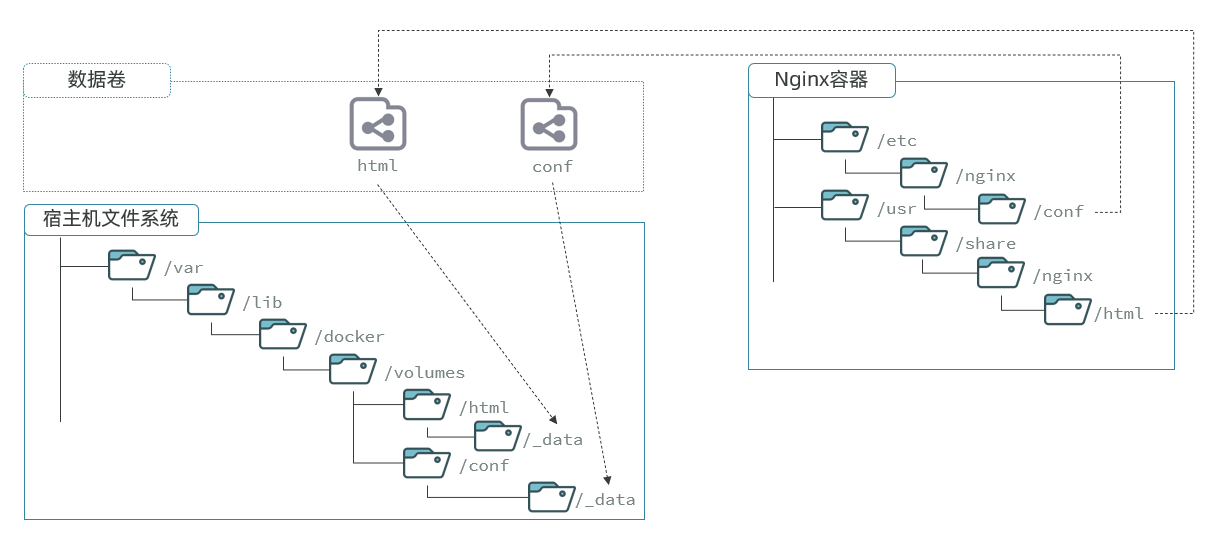

在上图中：

- 我们创建了两个数据卷：conf、html

- Nginx容器内部的conf目录和html目录分别与两个数据卷关联。

- 而数据卷conf和html分别指向了宿主机的/var/lib/docker/volumes/conf/_data目录和/var/lib/docker/volumes/html/_data目录

这样以来，容器内的conf和html目录就 与宿主机的conf和html目录关联起来，我们称为挂载。

此时，我们操作宿主机的/var/lib/docker/volumes/html/_data就是在操作容器内的/usr/share/nginx/html/_data目录。只要我们将静态资源放入宿主机对应目录，就可以被Nginx代理了。

**讲义提示**

> 小提示：

> /var/lib/docker/volumes这个目录就是默认的存放所有容器数据卷的目录，其下再根据数据卷名称创建新目录，格式为/数据卷名/_data。

> 为什么不让容器目录直接指向宿主机目录呢？

> - 因为直接指向宿主机目录就与宿主机强耦合了，如果切换了环境，宿主机目录就可能发生改变了。由于容器一旦创建，目录挂载就无法修改，这样容器就无法正常工作了。

> - 但是容器指向数据卷，一个逻辑名称，而数据卷再指向宿主机目录，就不存在强耦合。如果宿主机目录发生改变，只要改变数据卷与宿主机目录之间的映射关系即可。

> 不过，我们通过由于数据卷目录比较深，不好寻找，通常我们也允许让容器直接与宿主机目录挂载而不使用数据卷，具体参考2.2.3小节。

#### 命令

数据卷的相关命令有：

| 列1 | 列2 | 列3 |
| --- | --- | --- |
| 命令 | 说明 | 文档地址 |
| docker volume create | 创建数据卷 | docker volume create |
| docker volume ls | 查看所有数据卷 | docs.docker.com |
| docker volume rm | 删除指定数据卷 | docs.docker.com |
| docker volume inspect | 查看某个数据卷的详情 | docs.docker.com |
| docker volume prune | 清除数据卷 | docker volume prune |

注意：容器与数据卷的挂载要在创建容器时配置，对于创建好的容器，是不能设置数据卷的。而且创建容器的过程中，数据卷会自动创建。

教学演示环节：演示一下nginx的html目录挂载

```powershell
# 1.首先创建容器并指定数据卷，注意通过 -v 参数来指定数据卷
docker run -d --name nginx -p 80:80 -v html:/usr/share/nginx/html nginx:1.20.2

# 2.然后查看数据卷
docker volume ls


# 3.查看数据卷详情
docker volume inspect html


# 4.查看/var/lib/docker/volumes/html/_data目录
ll /var/lib/docker/volumes/html/_data


# 5.进入该目录，并随意修改index.html内容
cd /var/lib/docker/volumes/html/_data
vi index.html

# 6.打开页面，查看效果

# 7.进入容器内部，查看/usr/share/nginx/html目录内的文件是否变化
docker exec -it nginx bash
```

教学演示环节：演示一下MySQL的匿名数据卷

```powershell
# 1.查看MySQL容器详细信息
docker inspect mysql

# 关注其中.Config.Volumes部分和.Mounts部分
```

我们关注两部分内容，第一是.Config.Volumes部分：

```powershell
{
  "Config": {
    // ... 略
    "Volumes": {
      "/var/lib/mysql": {}
    }
    // ... 略
  }
}
```

可以发现这个容器声明了一个本地目录，需要挂载数据卷，但是数据卷未定义。这就是匿名卷。

然后，我们再看结果中的.Mounts部分：

```powershell
{
  "Mounts": [
    {
      "Type": "volume",
      "Name": "29524ff09715d3688eae3f99803a2796558dbd00ca584a25a4bbc193ca82459f",
      "Source": "/var/lib/docker/volumes/29524ff09715d3688eae3f99803a2796558dbd00ca584a25a4bbc193ca82459f/_data",
      "Destination": "/var/lib/mysql",
      "Driver": "local",
    }
  ]
}
```

可以发现，其中有几个关键属性：

- Name：数据卷名称。由于定义容器未设置容器名，这里的就是匿名卷自动生成的名字，一串hash值。

- Source：宿主机目录

- Destination : 容器内的目录

上述配置是将容器内的/var/lib/mysql这个目录，与数据卷29524ff09715d3688eae3f99803a2796558dbd00ca584a25a4bbc193ca82459f挂载。于是在宿主机中就有了/var/lib/docker/volumes/29524ff09715d3688eae3f99803a2796558dbd00ca584a25a4bbc193ca82459f/_data这个目录。这就是匿名数据卷对应的目录，其使用方式与普通数据卷没有差别。

接下来，可以查看该目录下的MySQL的data文件：

```powershell
ls -l /var/lib/docker/volumes/29524ff09715d3688eae3f99803a2796558dbd00ca584a25a4bbc193ca82459f/_data
```

注意：每一个不同的镜像，将来创建容器后内部有哪些目录可以挂载，可以参考DockerHub对应的页面 。

#### 挂载本地目录或文件

可以发现，数据卷的目录结构较深，如果我们去操作数据卷目录会不太方便。在很多情况下，我们会直接将容器目录与宿主机指定目录挂载。挂载语法与数据卷类似：

```powershell
# 挂载本地目录
-v 本地目录:容器内目录

# 挂载本地文件
-v 本地文件:容器内文件
```

注意：本地目录或文件必须以 / 或 ./开头，如果直接以名字开头，会被识别为数据卷名而非本地目录名。

例如：

```powershell
-v mysql:/var/lib/mysql # 会被识别为一个数据卷叫mysql，运行时会自动创建这个数据卷

-v ./mysql:/var/lib/mysql # 会被识别为当前目录下的mysql目录，运行时如果不存在会创建目录
```

教学演示，删除并重新创建mysql容器，并完成本地目录挂载：

- 挂载/root/mysql/data到容器内的/var/lib/mysql目录

- 挂载/root/mysql/init到容器内的/docker-entrypoint-initdb.d目录（初始化的SQL脚本目录）

- 挂载/root/mysql/conf到容器内的/etc/mysql/conf.d目录（这个是MySQL配置文件目录）

在课前资料中已经准备好了mysql 的init目录、conf目录、data目录，可以直接将其上传到Linux服务器中的 /root/mysql 目录下。

最终执行的指令如下：

```powershell
docker run -d \
--name mysql \
-p 3307:3306 \
-e MYSQL_ROOT_PASSWORD=123 \
-e TZ=Asia/Shanghai \
-v /root/mysql/data:/var/lib/mysql \
-v /root/mysql/init:/docker-entrypoint-initdb.d \
-v /root/mysql/conf:/etc/mysql/conf.d \
mysql:8
```

### 自定义镜像

> **补充｜构建安全。** 缩小基础镜像、使用多阶段构建、加入 `.dockerignore`，不要在 Dockerfile 或镜像层中写入密码、AccessKey 和生产配置。

前面我们一直在使用别人准备好的镜像，那如果我要部署一个Java项目，把它打包为一个镜像该怎么做呢？ 那接下来，我们就来介绍一下如何自定义镜像。

#### 镜像结构

要想自己构建镜像，必须先了解镜像的结构。

之前我们说过，镜像之所以能让我们快速跨操作系统部署应用而忽略其运行环境、配置，就是因为镜像中包含了程序运行需要的系统函数库、环境、配置、依赖。

因此，自定义镜像本质就是依次准备好程序运行的基础环境、依赖、应用本身、运行配置等文件，并且打包而成。

举个例子，我们要从0部署一个Java应用，大概流程是这样：

- 准备一个linux服务（CentOS或者Ubuntu均可）

- 安装并配置JDK

- 上传Jar包

- 运行jar包

那因此，我们打包镜像也是分成这么几步：

- 准备Linux运行环境（java项目并不需要完整的操作系统，仅仅是基础运行环境即可）

- 安装并配置JDK

- 拷贝jar包

- 配置启动脚本

上述步骤中的每一次操作其实都是在生产一些文件（系统运行环境、函数库、配置最终都是磁盘文件），所以镜像就是一堆文件的集合。

但需要注意的是，镜像文件不是随意堆放的，而是按照操作的步骤分层叠加而成，每一层形成的文件都会单独打包并标记一个唯一id，称为Layer（层）。这样，如果我们构建时用到的某些层其他人已经制作过，就可以直接拷贝使用这些层，而不用重复制作。

例如，第一步中需要的Linux运行环境，通用性就很强，所以Docker官方就制作了这样的只包含Linux运行环境的镜像。我们在制作java镜像时，就无需重复制作，直接使用Docker官方提供的CentOS或Ubuntu镜像作为基础镜像。然后再搭建其它层即可，这样逐层搭建，最终整个Java项目的镜像结构如图所示：

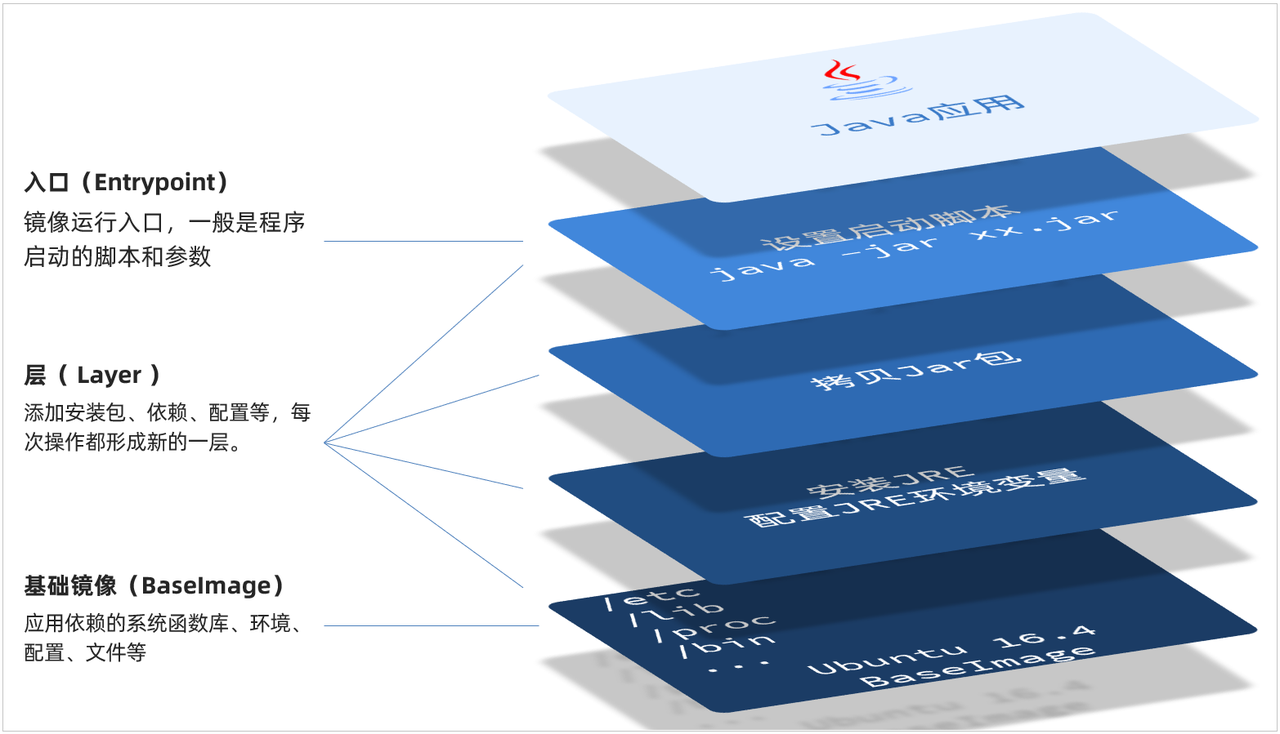

#### Dockerfile

> **补充｜缓存与启动。** 将依赖文件复制和源码复制分层，减少重复下载；使用明确的 `ENTRYPOINT` 或 `CMD`，并让程序以前台进程运行。

由于制作镜像的过程中，需要逐层处理和打包，比较复杂，所以Docker就提供了自动打包镜像的功能。我们只需要将打包的过程，每一层要做的事情用固定的语法写下来，交给Docker去执行即可。而这种记录镜像结构的文件就称为Dockerfile。

其中的语法比较多，比较常用的有：

| 列1 | 列2 | 列3 |
| --- | --- | --- |
| 指令 | 说明 | 示例 |
| FROM | 指定基础镜像 | FROM centos:7 |
| ENV | 设置环境变量，可在后面指令使用 | ENV key value |
| COPY | 拷贝本地文件到镜像的指定目录 | COPY ./xx.jar /tmp/app.jar |
| RUN | 执行Linux的shell命令，一般是安装过程的命令 | RUN yum install gcc |
| EXPOSE | 指定容器运行时监听的端口，是给镜像使用者看的 | EXPOSE 8080 |
| ENTRYPOINT | 镜像中应用的启动命令，容器运行时调用 | ENTRYPOINT java -jar xx.jar |

例如，要基于 centos:7 镜像来构建一个Java应用，其Dockerfile内容如下：

```powershell
# 使用 CentOS 7 作为基础镜像
FROM centos:7

# 添加 JDK 到镜像中
COPY jdk17.tar.gz /usr/local/
RUN tar -xzf /usr/local/jdk17.tar.gz -C /usr/local/ &&  rm /usr/local/jdk17.tar.gz

# 设置环境变量
ENV JAVA_HOME=/usr/local/jdk-17.0.10
ENV PATH=$JAVA_HOME/bin:$PATH

# 创建应用目录
RUN mkdir -p /app
WORKDIR /app

# 复制应用 JAR 文件到容器
COPY app.jar app.jar

# 暴露端口
EXPOSE 8080

# 运行命令
ENTRYPOINT ["java","-Djava.security.egd=file:/dev/./urandom","-jar","/app/app.jar"]
```

Dockerfile文件编写好了之后，就可以使用如下命令来构建镜像了。

```powershell
docker build -t 镜像名 .
```

- -t ：是给镜像起名，格式依然是repository:tag的格式，不指定tag时，默认为latest

- .  ：是指定Dockerfile所在目录，如果就在当前目录，则指定为"."

演示:

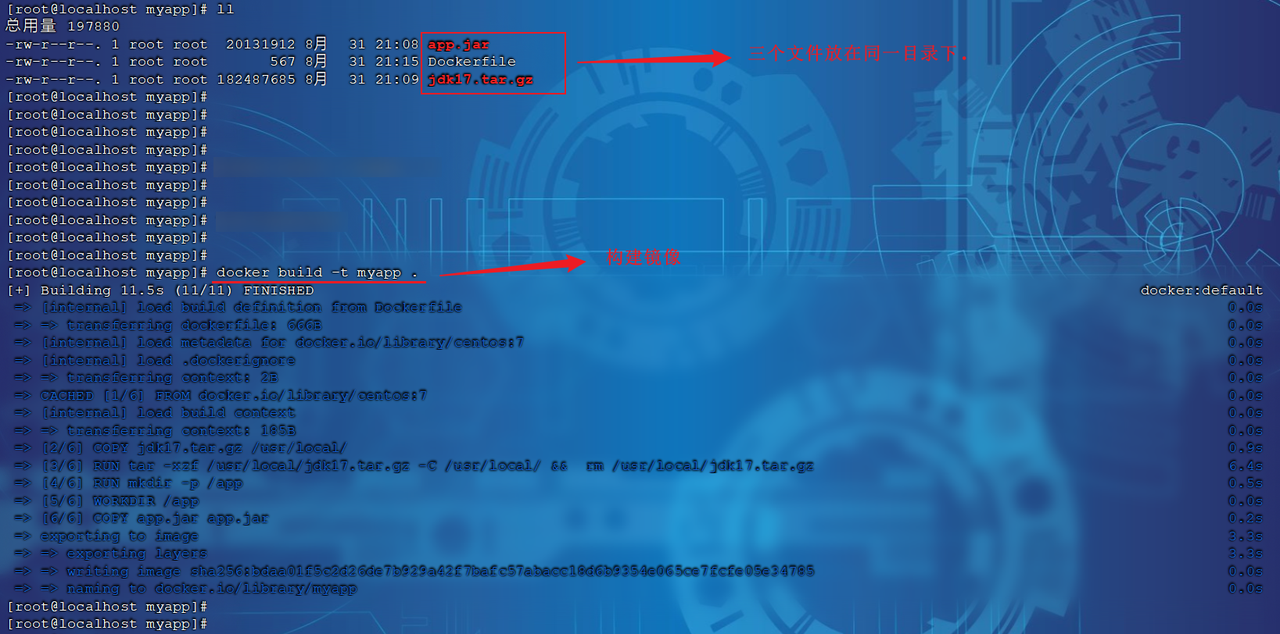

### 网络

> **补充｜服务发现。** 同一个 Compose 网络中的服务可以使用服务名互相访问，例如后端连接 MySQL 使用 `mysql:3306`，不要把容器内连接地址写成宿主机 `localhost`。

上节课我们创建了一个Java项目的容器，而Java项目往往需要访问其它各种中间件，例如MySQL、Redis等。现在，我们的容器之间能否互相访问呢？我们来测试一下

首先，我们查看下MySQL容器的详细信息，重点关注其中的网络IP地址：

```powershell
# 1.用基本命令，寻找Networks.bridge.IPAddress属性
docker inspect mysql

# 也可以使用format过滤结果
docker inspect --format='{{range .NetworkSettings.Networks}}{{println .IPAddress}}{{end}}' mysql

# 得到IP地址如下：
172.17.0.2

# 2.然后通过命令进入dd容器
docker exec -it dd bash

# 3.在容器内，通过ping命令测试网络
ping 172.17.0.2

# 结果
PING 172.17.0.2 (172.17.0.2) 56(84) bytes of data.
64 bytes from 172.17.0.2: icmp_seq=1 ttl=64 time=0.053 ms
64 bytes from 172.17.0.2: icmp_seq=2 ttl=64 time=0.059 ms
64 bytes from 172.17.0.2: icmp_seq=3 ttl=64 time=0.058 ms
```

发现可以互联，没有问题。

但是，容器的网络IP其实是一个虚拟的IP，其值并不固定与某一个容器绑定，如果我们在开发时写死某个IP，而在部署时很可能MySQL容器的IP会发生变化，连接会失败。

常见命令有：

| 列1 | 列2 |
| --- | --- |
| 命令 | 说明 |
| docker network create | 创建一个网络 |
| docker network ls | 查看所有网络 |
| docker network rm | 删除指定网络 |
| docker network prune | 清除未使用的网络 |
| docker network connect | 使指定容器连接加入某网络 |
| docker network disconnect | 使指定容器连接离开某网络 |
| docker network inspect | 查看网络详细信息 |

教学演示：自定义网络

```powershell
# 1.首先通过命令创建一个网络
docker network create itheima

# 2.然后查看网络
docker network ls

# 结果：
NETWORK ID     NAME      DRIVER    SCOPE
639bc44d0a87   bridge    bridge    local
403f16ec62a2   itheima     bridge    local
0dc0f72a0fbb   host      host      local
cd8d3e8df47b   none      null      local
# 其中，除了itheima以外，其它都是默认的网络


# 3.让 myapp 和 mysql 都加入该网络
# 3.1.mysql容器，加入 itheima 网络
docker network connect itheima mysql

# 3.2.myapp容器，也就是我们的java项目, 加入 itheima 网络
docker network connect itheima myapp


# 4.进入dd容器，尝试利用别名访问db
# 4.1.进入容器
docker exec -it myapp bash

# 4.2.用容器名访问
ping mysql

# 结果：
PING mysql (172.18.0.2) 56(84) bytes of data.
64 bytes from mysql.itheima (172.18.0.2): icmp_seq=1 ttl=64 time=0.044 ms
64 bytes from mysql.itheima (172.18.0.2): icmp_seq=2 ttl=64 time=0.054 ms
```

OK，现在无需记住IP地址也可以实现容器互联了。

## 项目部署

> **补充｜发布顺序。** 先构建并验证镜像，再启动数据库和后端，最后启动前端与反向代理；每次发布保留镜像标签和 Compose 配置，便于回滚。

### 部署服务端

> **补充｜配置注入。** Spring Boot 的数据库地址、端口、OSS 密钥等配置通过 Compose `environment`、`.env` 或 secrets 注入，避免提交到代码仓库。

- 需求：将我们开发的 tlias-web-management 项目打包为镜像，并部署。

- 步骤：

1. 修改项目的配置文件，修改数据库服务地址（打包package）。

1. 编写Dockerfile文件（AI辅助）。

1. 构建Docker镜像，部署Docker容器，运行测试。

1). 修改项目的配置文件，修改数据库服务地址（打包package）。

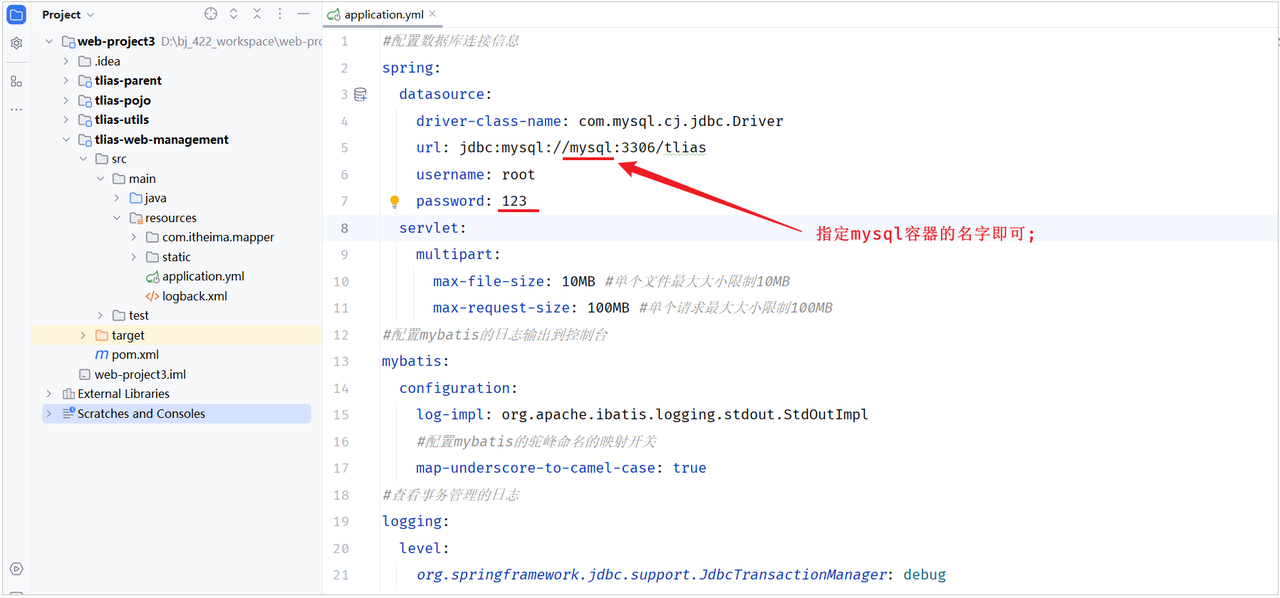

然后，执行maven中的package生命周期，进行打包(跳过测试)，并将打包后的jar包命名为 tlias.jar 。

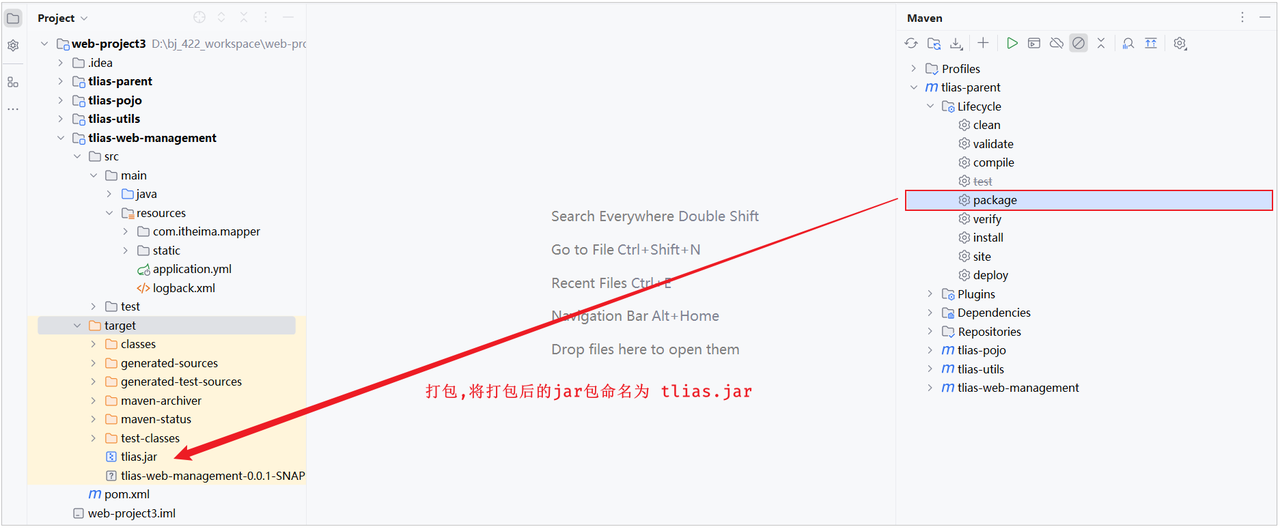

2). 编写Dockerfile文件（AI辅助）。

文件名 Dockerfile:

```powershell
# 使用 CentOS 7 作为基础镜像
FROM centos:7

# 添加 JDK 到镜像中
COPY jdk17.tar.gz /usr/local/
RUN tar -xzf /usr/local/jdk17.tar.gz -C /usr/local/ &&  rm /usr/local/jdk17.tar.gz

# 设置环境变量
ENV JAVA_HOME=/usr/local/jdk-17.0.10
ENV PATH=$JAVA_HOME/bin:$PATH

# 阿里云OSS环境变量
ENV OSS_ACCESS_KEY_ID=LTAI5tP6dc4cvccdvvySE39X
ENV OSS_ACCESS_KEY_SECRET=ZSyIT31qhxIkS0dH1H9WzHqPiyM3Ot

#统一编码
ENV LANG=en_US.UTF-8
ENV LANGUAGE=en_US:en
ENV LC_ALL=en_US.UTF-8

# 创建应用目录
RUN mkdir -p /tlias
WORKDIR /tlias

# 复制应用 JAR 文件到容器
COPY  tlias.jar  tlias.jar

# 暴露端口
EXPOSE 8080

# 运行命令
ENTRYPOINT ["java","-jar","/tlias/tlias.jar"]
```

由于项目要运行，需要依赖jdk的环境，所以这里我们需要将tlias.jar，jdk17.tar.gz，Dockerfile三个文件，上传到Linux服务器的 /root/tlias 目录下（如果没有这个目录，提前创建好）。

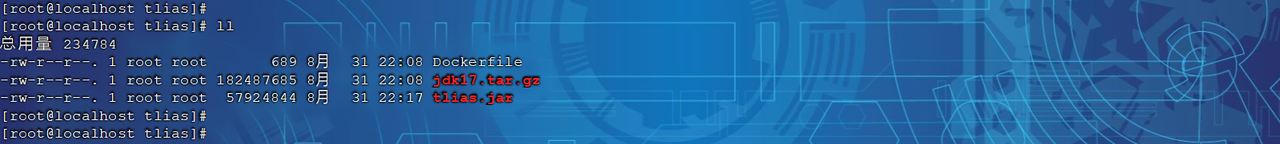

3). 构建Docker镜像，部署Docker容器，运行测试。

- 构建Docker镜像

```powershell
docker build -t tlias:1.0 .
```

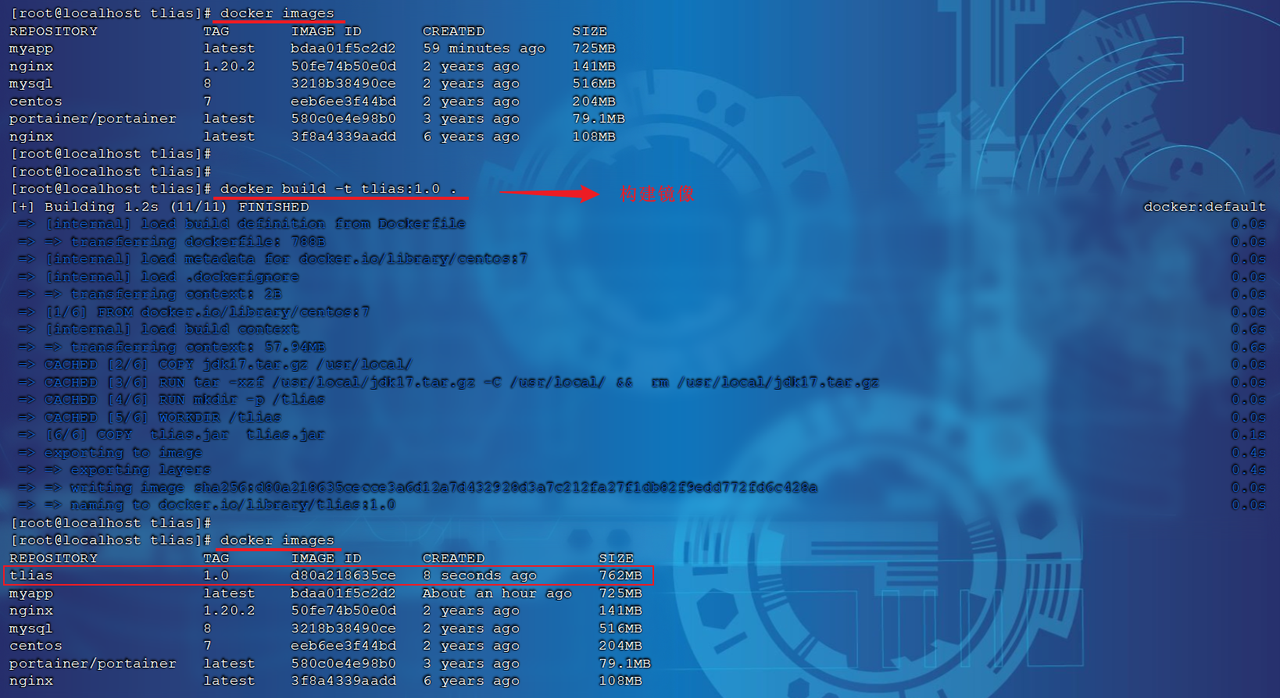

- 部署Docker容器

```powershell
docker run -d --name tlias-server --network itheima -p 8080:8080  tlias:1.0
```

**讲义提示**

> --network  itheima ：将创建的容器，加入到itheima网络，就可以和itheima网络中的容器通信了。

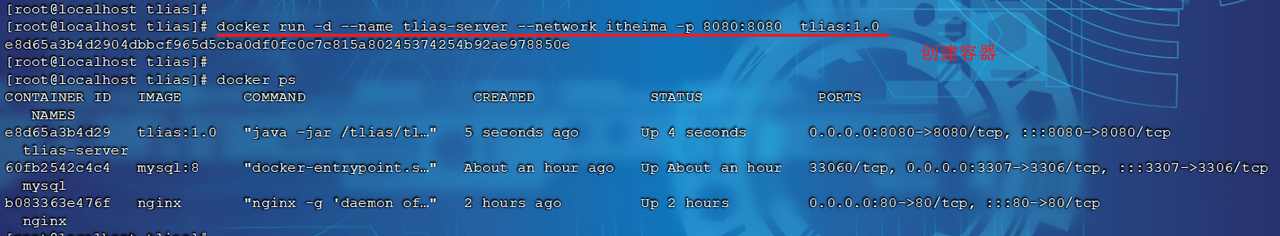

通过 docker logs -f 容器名，就可以查看容器的运行日志。

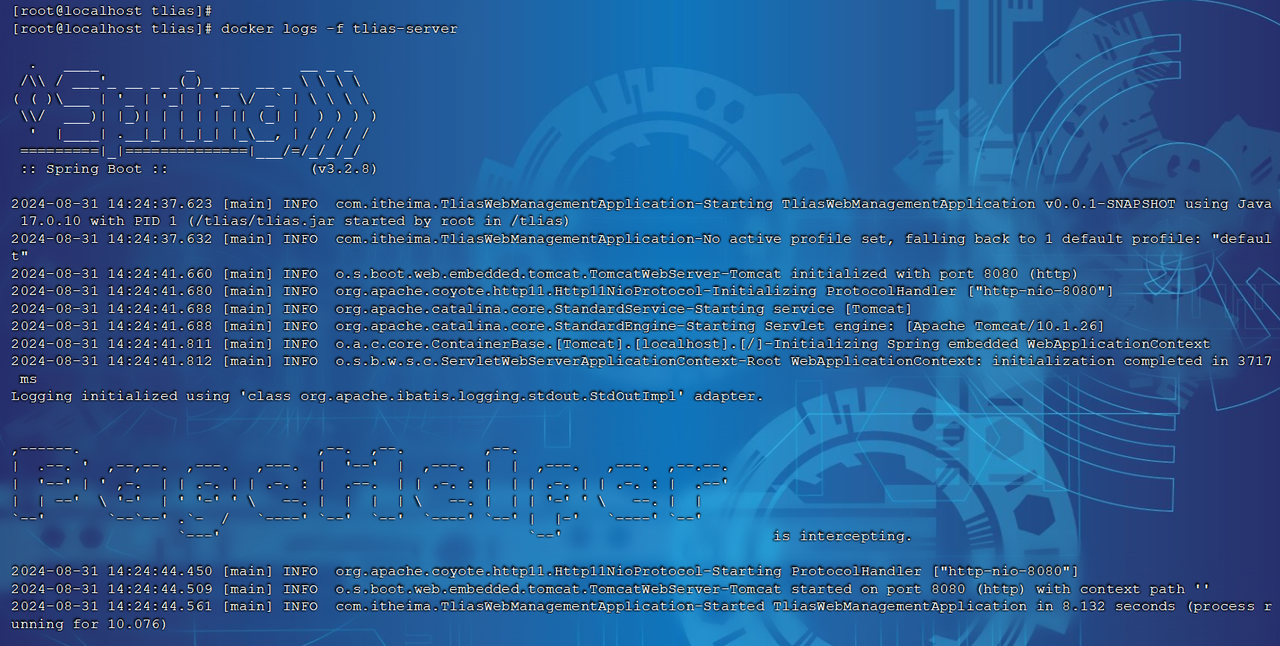

这样后端服务，就已经启动起来了。

### 部署前端

> **补充｜静态资源。** 前端镜像只保留构建后的 `dist` 和 Nginx 配置；通过反向代理统一暴露入口，避免直接暴露后端容器端口。

- 需求：创建一个新的nginx容器，将资料中提供的前端项目的静态资源部署到nginx中。

- 步骤：

- 在宿主机上准备静态文件及配置文件存放目录(在 /usr/local 目录下创建 tlias-web 目录)。

-v /usr/local/tlias-web/html:/usr/share/nginx/html

-v /usr/local/tlias-web/conf/nginx.conf:/etc/nginx/nginx.conf

- 部署nginx容器

1). 部署nginx容器（设置目录映射）。

- 将资 资料/04. 项目部署/前端项目 中的 目录html和 配置文件存放目录 conf，上传至服务器端的 /usr/local/tlias-web目录下。

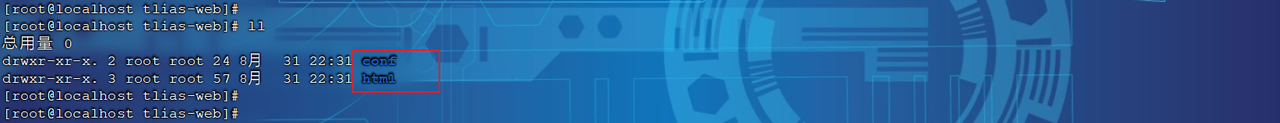

- 执行如下命令，部署nginx容器

```powershell
docker run -d \
--name nginx-tlias \
-v /usr/local/tlias-web/html:/usr/share/nginx/html \
-v /usr/local/tlias-web/conf/nginx.conf:/etc/nginx/nginx.conf \
--network itheima \
-p 80:80 \
nginx:1.20.2
```

前后端都部署完毕后，就可以打开浏览器，来测试一下。访问前端的nginx服务器 。

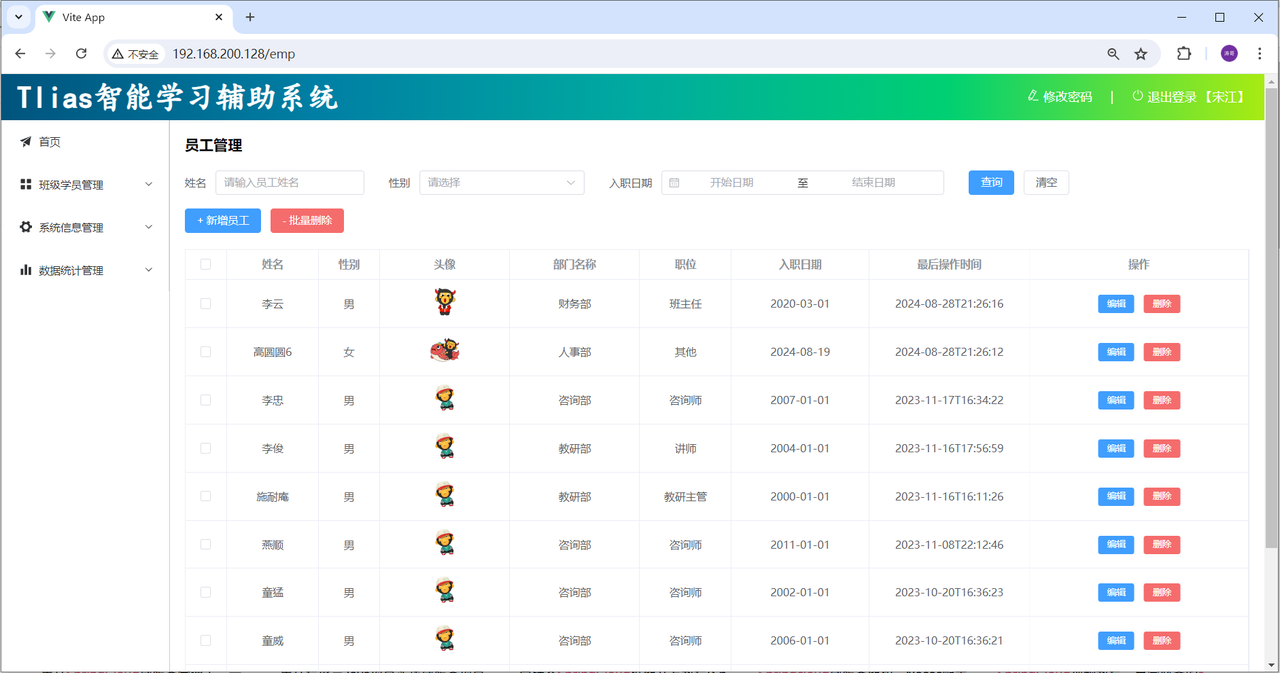

### DockerCompose

> **补充｜编排边界。** Compose 适合单机多容器部署；生产环境仍需配合健康检查、重启策略、日志轮转、备份和监控。

大家可以看到，我们部署一个简单的java项目，其中包含3个容器：

- MySQL

- Nginx

- Java项目

而稍微复杂的项目，其中还会有各种各样的其它中间件，需要部署的东西远不止3个。如果还像之前那样手动的逐一部署，就太麻烦了。

而Docker Compose就可以帮助我们实现多个相互关联的Docker容器的快速部署。它允许用户通过一个单独的 docker-compose.yml 模板文件（YAML 格式）来定义一组相关联的应用容器。

#### 基本语法

> **补充｜变量与版本。** 为 Compose 文件标记镜像版本和配置版本，使用 `.env` 管理环境差异，避免使用不受控的 `latest` 导致不可重复部署。

docker-compose文件中可以定义多个相互关联的应用容器，每一个应用容器被称为一个服务（service）。由于service就是在定义某个应用的运行时参数，因此与docker run参数非常相似。

举例来说，用docker run部署MySQL的命令如下：

```powershell
docker run -d \
--name nginx-tlias \
-p 80:80 \
-v /usr/local/app/html:/usr/share/nginx/html \
-v /usr/local/app/conf/nginx.conf:/etc/nginx/nginx.conf \  
--network itheima \
nginx:1.20.2
```

如果用docker-compose.yml文件来定义，就是这样：

```yaml
services:
  mysql:
    image: "nginx:1.20.2"
    container_name: nginx-tlias
    ports:
      - "80:80"
    volumes:
      - "/usr/local/app/html:/usr/share/nginx/html"
      - "/usr/local/app/conf/nginx.conf:/etc/nginx/nginx.conf"
    networks:
      - itheima
networks:
  itheima:
    name: itheima
```

对比如下：

| 列1 | 列2 | 列3 |
| --- | --- | --- |
| docker run 参数 | docker compose 指令 | 说明 |
| --name | container_name | 容器名称 |
| -p | ports | 端口映射 |
| -e | environment | 环境变量 |
| -v | volumes | 数据卷配置 |
| --network | networks | 网络 |

明白了其中的对应关系，相信编写docker-compose文件应该难不倒大家。

```yaml
services:
  mysql:
    image: mysql:8
    container_name: mysql
    ports:
      - "3307:3306"
    environment:
      TZ: Asia/Shanghai
      MYSQL_ROOT_PASSWORD: 123
    volumes:
      - "/usr/local/app/mysql/conf:/etc/mysql/conf.d"
      - "/usr/local/app/mysql/data:/var/lib/mysql"
      - "/usr/local/app/mysql/init:/docker-entrypoint-initdb.d"
    networks:
      - tlias-net
  tlias:
    build: 
      context: .
      dockerfile: Dockerfile
    container_name: tlias-server
    ports:
      - "8080:8080"
    networks:
      - tlias-net
    depends_on:
      - mysql
  nginx:
    image: nginx:1.20.2
    container_name: nginx
    ports:
      - "80:80"
    volumes:
      - "/usr/local/app/nginx/conf/nginx.conf:/etc/nginx/nginx.conf"
      - "/usr/local/app/nginx/html:/usr/share/nginx/html"
    depends_on:
      - tlias
    networks:
      - tlias-net
networks:
  tlias-net:
    name: itheima
```

#### 基础命令

> **补充｜常用闭环。** `docker compose up -d` 启动，`docker compose ps` 查看，`docker compose logs -f` 追踪，`docker compose down` 停止并删除容器；删除卷前先确认备份。

编写好docker-compose.yml文件，就可以部署项目了。语法如下：

```yaml
docker compose [OPTIONS] [COMMAND]
```

其中，OPTIONS和COMMAND都是可选参数，比较常见的有：

| 列1 | 列2 | 列3 |
| --- | --- | --- |
| 类型 | 参数或指令 | 说明 |
| Options | -f | 指定compose文件的路径和名称 |
|  | -p | 指定project名称。project就是当前compose文件中设置的多个service的集合，是逻辑概念 |
| Commands | up | 创建并启动所有service容器 |
|  | down | 停止并移除所有容器、网络 |
|  | ps | 列出所有启动的容器 |
|  | logs | 查看指定容器的日志 |
|  | stop | 停止容器 |
|  | start | 启动容器 |
|  | restart | 重启容器 |
|  | top | 查看运行的进程 |
|  | exec | 在指定的运行中容器中执行命令 |

#### 操作演示

1). 在 Linux 服务器的 /usr/local 目录下创建目录 app，并切换到 /usr/local/app 目录。

2). 上传资料中提供的 "资料/05. Docker Compose" 中的文件及文件夹到 /usr/local/app 目录中，如下所示：

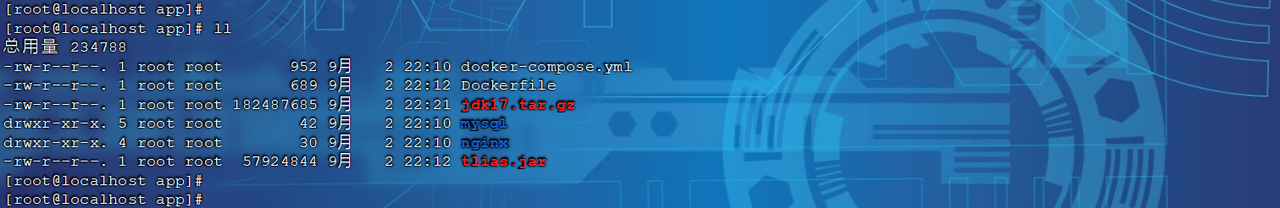

注意，资料中提供的Dockerfile文件中的阿里云OSS的 AccessKeyId，AccessKeySecret需要替换成自己的。

3). 执行如下指令，基于DockerCompose部署项目。

```yaml
docker compose up -d
```

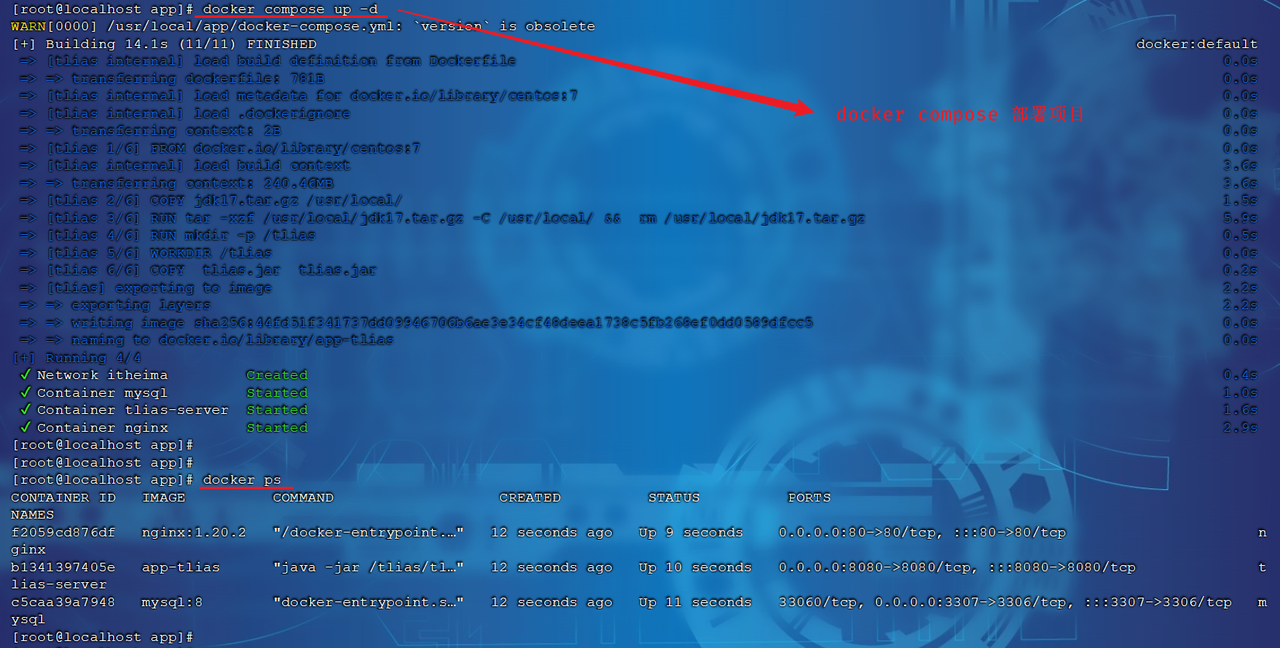

项目启动完毕之后，就可以启动服务器测试喽 。

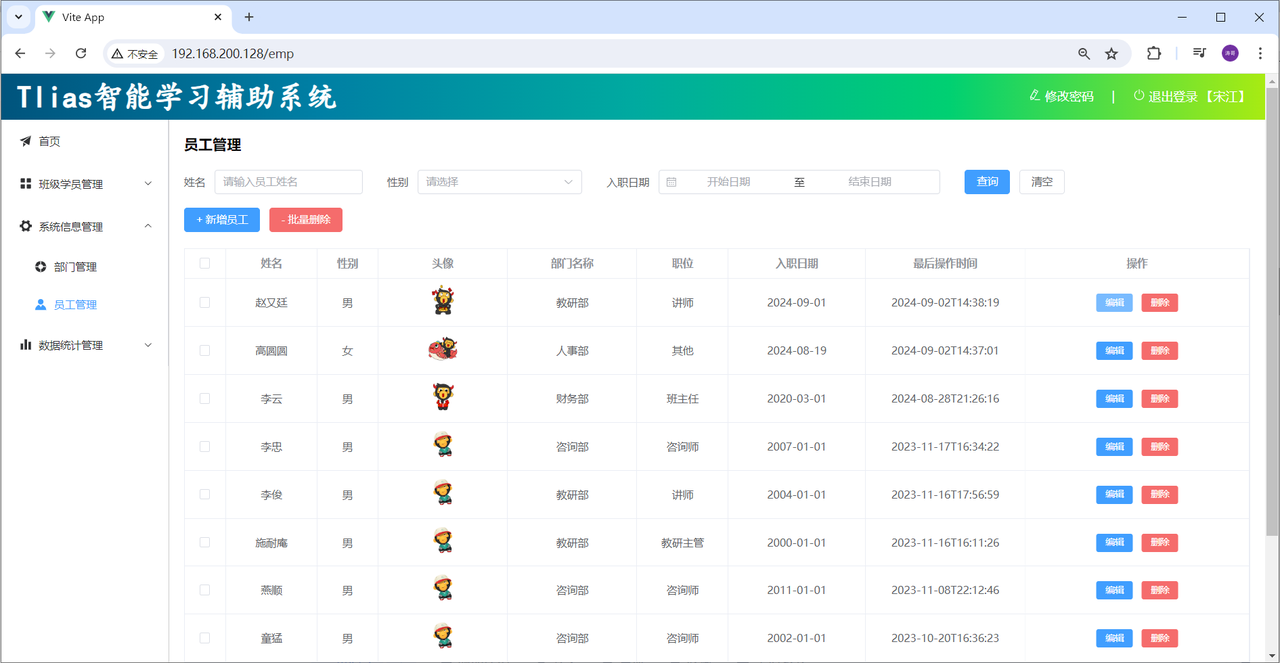

## 附录：Docker安装

> **补充｜安装后检查。** 安装完成后确认 Docker 服务开机自启、当前用户具备必要权限，并用一个最小 Nginx 容器完成拉取、启动、端口访问和清理验证。

### 卸载旧版

首先如果系统中已经存在旧的Docker，则先卸载：

```shell
yum remove docker \
    docker-client \
    docker-client-latest \
    docker-common \
    docker-latest \
    docker-latest-logrotate \
    docker-logrotate \
    docker-engine \
    docker-selinux 
```

### 配置Docker的yum库

首先要安装一个yum工具

```bash
sudo yum install -y yum-utils device-mapper-persistent-data lvm2
```

安装成功后，执行命令，配置Docker的yum源（已更新为阿里云源）：

```bash
sudo yum-config-manager --add-repo https://mirrors.aliyun.com/docker-ce/linux/centos/docker-ce.repo

sudo sed -i 's+download.docker.com+mirrors.aliyun.com/docker-ce+' /etc/yum.repos.d/docker-ce.repo
```

更新yum，建立缓存

```bash
sudo yum makecache fast
```

### 安装Docker

最后，执行命令，安装Docker

```bash
yum install -y docker-ce docker-ce-cli containerd.io docker-buildx-plugin docker-compose-plugin
```

### 启动和校验

```bash
# 启动Docker
systemctl start docker

# 停止Docker
systemctl stop docker

# 重启
systemctl restart docker

# 设置开机自启
systemctl enable docker

# 执行docker ps命令，如果不报错，说明安装启动成功
docker ps
```

### 配置镜像加速

> **补充｜供应链安全。** 镜像加速器应使用可信来源；生产环境固定基础镜像版本并定期扫描漏洞，避免未经审核的镜像进入发布链路。

镜像地址可能会变更，如果失效可以百度找最新的docker镜像。

配置镜像步骤如下：

```bash
# 创建目录
rm -f /etc/docker/daemon.json

# 复制内容
tee /etc/docker/daemon.json <<-'EOF'
{
    "registry-mirrors": [
        "http://hub-mirror.c.163.com",
        "https://mirrors.tuna.tsinghua.edu.cn",
        "http://mirrors.sohu.com",
        "https://ustc-edu-cn.mirror.aliyuncs.com",
        "https://ccr.ccs.tencentyun.com",
        "https://docker.m.daocloud.io",
        "https://docker.awsl9527.cn"
    ]
}
EOF

# 重新加载配置
systemctl daemon-reload

# 重启Docker
systemctl restart docker
```

## 复习速查与验收（补充）

| 知识点 | 记忆要点 | 常见误区 |
| --- | --- | --- |
| 镜像 | 只读模板，包含应用及运行环境 | 直接把容器当作永久数据存储 |
| 容器 | 镜像运行实例，具备隔离的进程、网络和文件系统 | 只看 `docker ps`，不检查退出容器 |
| 端口映射 | `-p 主机端口:容器端口` | 在容器内把服务地址写成宿主机 `localhost` |
| 数据卷 | 将数据生命周期从容器中分离 | 删除容器时误删数据库卷 |
| Dockerfile | 描述镜像构建步骤，注意层缓存和启动命令 | 把密码复制进镜像或使用过大的基础镜像 |
| Compose | 用 YAML 编排服务、网络、卷和环境变量 | 所有服务都使用 `latest`，无法稳定回滚 |
| 服务网络 | 同网络服务用服务名和容器端口通信 | 用宿主机端口替代容器内服务名 |
| 日志排障 | `docker logs`、`docker compose logs -f` | 容器启动失败却只反复执行 `up` |

### 跟练验收

1. 执行 `docker version`、`docker info` 和 `docker compose version`，确认运行环境。
2. 用 `docker run` 启动 MySQL，检查容器状态、端口映射、日志和客户端连接。
3. 为 MySQL 创建 named volume，删除并重建容器后确认数据仍然存在。
4. 编写后端 Dockerfile，构建镜像并用环境变量注入数据库和 OSS 配置。
5. 编写前端 Dockerfile 和 Nginx 配置，确认静态资源、history 回退和 `/api` 代理。
6. 使用 Compose 启动前端、后端、MySQL，确认服务名解析和容器网络通信。
7. 用 `docker compose ps`、`logs -f` 和健康检查完成一次故障定位。
8. 为镜像固定版本标签，保留上一版本配置并演练一次回滚。

### 自测问题

- 镜像、容器和数据卷分别解决什么问题？
- `docker run -p 3307:3306` 中两个端口分别属于谁？
- 为什么容器内连接 MySQL 要使用 `mysql:3306`，不能使用 `localhost`？
- Dockerfile 为什么要利用分层缓存并使用 `.dockerignore`？
- Compose 中环境变量、网络和卷如何共同完成多服务部署？
- 删除容器、删除镜像和删除卷的影响有什么不同？
- 为什么生产部署要固定镜像版本并保留回滚版本？